# 03 — Inventory Policy: Safety Stock, Reorder Points, EOQ
**Question:** how much stock should each product carry, when should it be reordered, and what is that worth in dollars?

**Approach:** a weekly-review **(R, s, Q)** policy. Every week, check stock; if the inventory position is at or below the reorder point *s*, order *Q* units.
- **Safety stock** = z × σ(weekly demand) × √(lead time + review period)
- **Reorder point** = average weekly demand × (lead time + review period) + safety stock
- **Order quantity (EOQ)** = √(2 × annual demand × ordering cost ÷ annual holding cost per unit)

The policy is then **back-tested on the actual weekly demand history** to confirm it delivers the target service level.

## Assumptions
The dataset has **no supplier lead times, on-hand stock or cost parameters**, so these are explicit, industry-typical assumptions. All of them can be changed in the Excel what-if model (`excel/inventory_policy_model.xlsx`).

| Parameter | Value | Why |
|---|---|---|
| Supplier lead time | 2 weeks | Typical for domestic distributor replenishment |
| Review period | 1 week | Weekly replenishment cycle |
| Service level (cycle) | A 98% · B 95% · C 90% | Protect the revenue that matters most |
| Holding cost | 25% of unit cost per year | Standard range is 20–30% (capital, storage, shrinkage) |
| Ordering cost | $50 per order | Purchasing, receiving and admin effort |
| Unit cost | Median of (item total − profit) ÷ qty | Derived from the order data |
| **Current-state baseline** | **4 weeks of average demand as safety stock + monthly orders, for every product** | A common blanket rule when there is no segmentation |

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy.stats import norm
import chart_style as cs
cs.apply()

LEAD_WEEKS, REVIEW_WEEKS = 2, 1
PROTECT = LEAD_WEEKS + REVIEW_WEEKS
SERVICE = {'A': 0.98, 'B': 0.95, 'C': 0.90}
HOLDING_RATE, ORDER_COST = 0.25, 50
BASELINE_SS_WEEKS = 4

seg = pd.read_csv('../results/product_segments.csv')
df = pd.read_csv('../data/processed/order_lines_clean.csv', parse_dates=['order_date'])
m = df[(df.in_model_window == 1) & (df.is_cancelled == 0)].copy()
m['unit_cost'] = (m['order_item_total'] - m['order_item_profit']) / m['order_item_quantity']
m['week'] = m['order_date'].dt.to_period('W')
weekly = m.groupby(['product_id', 'week'])['order_item_quantity'].sum()

p = seg[seg.enough_history].set_index('product_id').copy()
p['unit_cost'] = m.groupby('product_id')['unit_cost'].median()
print(f'Products with a statistical policy: {len(p)} of {len(seg)} (others have < 26 weeks of history)')
print(f'They cover {p.rev_share.sum():.1%} of revenue')

Products with a statistical policy: 54 of 100 (others have < 26 weeks of history)
They cover 98.3% of revenue


## 1. Optimised policy

In [2]:
p['service_level'] = p['abc'].map(SERVICE)
p['z'] = norm.ppf(p['service_level'])
p['annual_demand'] = p['avg_weekly_units'] * 52
p['holding_cost_unit'] = HOLDING_RATE * p['unit_cost']

p['safety_stock'] = np.ceil(p['z'] * p['sd_weekly_units'] * np.sqrt(PROTECT))
p['reorder_point'] = np.ceil(p['avg_weekly_units'] * PROTECT + p['safety_stock'])
p['eoq'] = np.ceil(np.sqrt(2 * p['annual_demand'] * ORDER_COST / p['holding_cost_unit'])).clip(lower=1)
p['orders_per_year'] = p['annual_demand'] / p['eoq']
p['weeks_of_cover_ss'] = p['safety_stock'] / p['avg_weekly_units']

cols = ['product_name', 'segment', 'avg_weekly_units', 'sd_weekly_units', 'unit_cost', 'service_level',
        'safety_stock', 'reorder_point', 'eoq', 'orders_per_year', 'weeks_of_cover_ss']
p.sort_values('revenue', ascending=False)[cols].head(12).round(1)

,product_name,segment,avg_weekly_units,sd_weekly_units,unit_cost,service_level,safety_stock,reorder_point,eoq,orders_per_year,weeks_of_cover_ss
product_id,,,,,,,,,,,
1004,Field & Stream Sportsman 16 Gun Fire Safe,AX,115.1,12.0,265.6,1.0,43.0,389.0,95.0,63.0,0.4
365,Perfect Fitness Perfect Rip Deck,AX,489.3,43.8,39.8,1.0,156.0,1624.0,506.0,50.3,0.3
957,Diamondback Women's Serene Classic Comfort Bi,AX,91.3,8.7,199.5,1.0,31.0,305.0,98.0,48.4,0.3
191,Nike Men's Free 5.0+ Running Shoe,AX,243.2,29.8,66.5,1.0,107.0,837.0,276.0,45.8,0.4
502,Nike Men's Dri-FIT Victory Golf Polo,AX,417.7,43.8,33.1,1.0,156.0,1410.0,513.0,42.3,0.4
1073,Pelican Sunstream 100 Kayak,AX,102.9,11.4,133.2,1.0,41.0,350.0,127.0,42.1,0.4
1014,O'Brien Men's Neoprene Life Vest,AX,383.8,44.0,33.2,1.0,157.0,1309.0,491.0,40.6,0.4
403,Nike Men's CJ Elite 2 TD Football Cleat,BX,147.5,15.6,86.1,1.0,45.0,488.0,189.0,40.6,0.3
627,Under Armour Girls' Toddler Spine Surge Runni,BX,210.8,28.2,26.8,1.0,81.0,714.0,405.0,27.1,0.4


For the stable A-products, about **0.4 weeks** of safety stock is enough to hit 98%, because their demand barely moves. The blanket rule holds **4 weeks**.

## 2. Baseline vs optimised: inventory value and annual cost

In [3]:
# Baseline: blanket 4-week safety stock, monthly orders
p['ss_base'] = np.ceil(BASELINE_SS_WEEKS * p['avg_weekly_units'])
p['q_base'] = np.ceil(p['annual_demand'] / 12)
p['rop_base'] = np.ceil(p['avg_weekly_units'] * PROTECT + p['ss_base'])

for tag, ss, q in [('base', 'ss_base', 'q_base'), ('opt', 'safety_stock', 'eoq')]:
    p[f'avg_inv_value_{tag}'] = (p[q] / 2 + p[ss]) * p['unit_cost']        # cycle stock + safety stock, at cost
    p[f'ss_value_{tag}'] = p[ss] * p['unit_cost']
    p[f'holding_cost_{tag}'] = p[f'avg_inv_value_{tag}'] * HOLDING_RATE
    p[f'ordering_cost_{tag}'] = p['annual_demand'] / p[q] * ORDER_COST
    p[f'total_cost_{tag}'] = p[f'holding_cost_{tag}'] + p[f'ordering_cost_{tag}']

summary = pd.DataFrame({
    'Baseline (blanket rule)': [p.ss_value_base.sum(), p.avg_inv_value_base.sum(), p.holding_cost_base.sum(), p.ordering_cost_base.sum(), p.total_cost_base.sum()],
    'Optimised (ABC-XYZ policy)': [p.ss_value_opt.sum(), p.avg_inv_value_opt.sum(), p.holding_cost_opt.sum(), p.ordering_cost_opt.sum(), p.total_cost_opt.sum()],
}, index=['Safety stock value', 'Average inventory value', 'Annual holding cost', 'Annual ordering cost', 'Total annual inventory cost'])
summary['Change'] = summary.iloc[:, 1] - summary.iloc[:, 0]
summary['Change %'] = (summary['Change'] / summary.iloc[:, 0] * 100).round(0)
summary.round(0)

,Baseline (blanket rule),Optimised (ABC-XYZ policy),Change,Change %
Safety stock value,600046.0,64506.0,-535539.0,-89.0
Average inventory value,924949.0,183792.0,-741157.0,-80.0
Annual holding cost,231237.0,45948.0,-185289.0,-80.0
Annual ordering cost,31930.0,29640.0,-2291.0,-7.0
Total annual inventory cost,263168.0,75588.0,-187580.0,-71.0


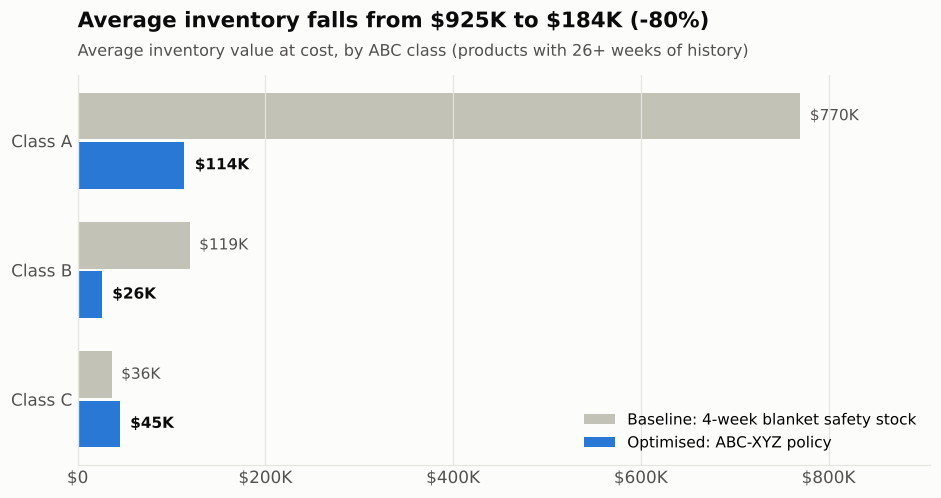

In [4]:
by_cls = p.groupby('abc')[['avg_inv_value_base', 'avg_inv_value_opt']].sum()
fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(by_cls))[::-1]
ax.barh(y + 0.19, by_cls['avg_inv_value_base'], height=0.36, color=cs.GREY, label='Baseline: 4-week blanket safety stock')
ax.barh(y - 0.19, by_cls['avg_inv_value_opt'], height=0.36, color=cs.BLUE, label='Optimised: ABC-XYZ policy')
for yy, (b, o) in zip(y, by_cls.values):
    ax.text(b, yy + 0.19, f'  {cs.money(b)}', va='center', color=cs.INK_2, fontsize=10)
    ax.text(o, yy - 0.19, f'  {cs.money(o)}', va='center', color=cs.INK, fontsize=10, fontweight='bold')
ax.set_yticks(y, [f'Class {c}' for c in by_cls.index]); ax.xaxis.set_major_formatter(cs.money_fmt)
ax.grid(axis='y', visible=False); ax.set_xlim(0, by_cls.values.max() * 1.18)
ax.legend(loc='lower right')
tot_b, tot_o = p.avg_inv_value_base.sum(), p.avg_inv_value_opt.sum()
cs.titles(ax, f'Average inventory falls from {cs.money(tot_b)} to {cs.money(tot_o)} ({(tot_o / tot_b - 1):.0%})',
          'Average inventory value at cost, by ABC class (products with 26+ weeks of history)')
plt.savefig('../images/03_inventory_value_baseline_vs_optimised.png'); plt.show()

**Why such a large drop?** The A-products have very stable demand, so a statistical safety stock is a fraction of a 4-week blanket rule. C-class average inventory rises slightly, because EOQ orders cheap, slow items in larger, less frequent batches, which lowers their ordering cost.

## 3. Back-test: does the leaner policy still hit the service level?
A smaller stock is only worth it if customers still get their orders. Each product's policy is replayed against its **actual weekly demand**:
start at reorder point + Q, receive orders after the lead time, serve demand from stock, and reorder whenever the inventory position falls to the reorder point.

In [5]:
def simulate(demand, rop, q, lead=LEAD_WEEKS):
    on_hand, pipeline, served, history, positions = rop + q, [], 0, [], []
    stockout_weeks = 0
    for t, d in enumerate(demand):
        on_hand += sum(qty for arrive, qty in pipeline if arrive == t)
        pipeline = [(a, qty) for a, qty in pipeline if a > t]
        sold = min(on_hand, d); served += sold; on_hand -= sold
        stockout_weeks += sold < d
        position = on_hand + sum(qty for _, qty in pipeline)
        while position <= rop:
            pipeline.append((t + lead + 1, q)); position += q
        history.append(on_hand); positions.append(position)
    return served / demand.sum(), 1 - stockout_weeks / len(demand), (history, positions)

bt = []
for pid, r in p.iterrows():
    s = weekly.loc[pid]
    s = s.reindex(pd.period_range(s.index.min(), s.index.max(), freq='W'), fill_value=0)
    fill_o, csl_o, _ = simulate(s.values, r.reorder_point, r.eoq)
    fill_b, csl_b, _ = simulate(s.values, r.rop_base, r.q_base)
    bt.append({'product_id': pid, 'fill_rate_opt': fill_o, 'weeks_in_stock_opt': csl_o, 'fill_rate_base': fill_b, 'weeks_in_stock_base': csl_b})
p = p.join(pd.DataFrame(bt).set_index('product_id'))

p.groupby('abc').agg(target=('service_level', 'first'), products=('eoq', 'size'),
                     fill_rate_optimised=('fill_rate_opt', 'mean'), weeks_in_stock_optimised=('weeks_in_stock_opt', 'mean'),
                     fill_rate_baseline=('fill_rate_base', 'mean')).round(3)

,target,products,fill_rate_optimised,weeks_in_stock_optimised,fill_rate_baseline
abc,,,,,
A,0.98,7,1.000,0.999,1.0
B,0.95,5,1.000,1.000,1.0
C,0.90,42,0.998,0.998,1.0


In [6]:
print('Lowest product fill rate under optimised policy:', f'{p.fill_rate_opt.min():.1%}')
print('Revenue-weighted fill rate (optimised):', f'{np.average(p.fill_rate_opt, weights=p.revenue):.2%}')

Lowest product fill rate under optimised policy: 97.4%
Revenue-weighted fill rate (optimised): 99.99%


**Result:** every class meets or beats its target, and the revenue-weighted fill rate stays above 99.9%. The baseline buys almost no extra service for about five times the inventory.

*Caveat: the back-test uses the same history the parameters were estimated from (in-sample), so it is optimistic. In production, parameters would be re-estimated monthly and monitored against actual fill rate.*

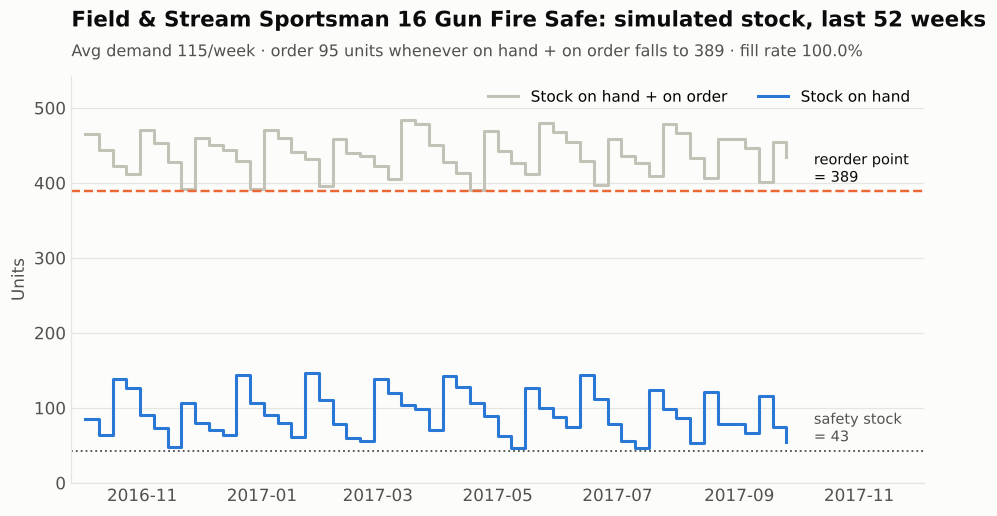

In [7]:
# Visual: one year of the top product under the optimised policy
pid = p.revenue.idxmax(); r = p.loc[pid]
s = weekly.loc[pid]; s = s.reindex(pd.period_range(s.index.min(), s.index.max(), freq='W'), fill_value=0)
_, _, (hist, pos) = simulate(s.values, r.reorder_point, r.eoq)
last = 52; x = s.index[-last:].to_timestamp(); h = hist[-last:]; ps = pos[-last:]

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.step(x, ps, where='post', color=cs.GREY, lw=2, label='Stock on hand + on order')
ax.step(x, h, where='post', color=cs.BLUE, lw=2, label='Stock on hand')
ax.axhline(r.reorder_point, color=cs.ORANGE, lw=1.6, ls='--')
ax.axhline(r.safety_stock, color=cs.INK_2, lw=1.2, ls=':')
lab_x = x[-1] + pd.Timedelta(weeks=2)
ax.text(lab_x, r.reorder_point + 6, f'reorder point\n= {r.reorder_point:.0f}', va='bottom', color=cs.INK, fontsize=9.5)
ax.text(lab_x, r.safety_stock + 6, f'safety stock\n= {r.safety_stock:.0f}', va='bottom', color=cs.INK_2, fontsize=9.5)
ax.set_xlim(x[0] - pd.Timedelta(weeks=1), x[-1] + pd.Timedelta(weeks=10))
ax.set_ylabel('Units'); ax.set_ylim(0, max(ps) * 1.12); ax.grid(axis='x', visible=False)
ax.legend(loc='upper right', ncol=2)
cs.titles(ax, f'{r.product_name.strip()}: simulated stock, last 52 weeks',
          f'Avg demand {r.avg_weekly_units:.0f}/week · order {r.eoq:.0f} units whenever on hand + on order falls to {r.reorder_point:.0f} · fill rate {r.fill_rate_opt:.1%}')
plt.savefig('../images/04_stock_simulation_top_product.png'); plt.show()

## 4. Save the policy table

In [8]:
out_cols = ['product_name', 'category', 'segment', 'abc', 'xyz', 'revenue', 'avg_weekly_units', 'sd_weekly_units', 'cv',
            'unit_cost', 'service_level', 'safety_stock', 'reorder_point', 'eoq', 'orders_per_year',
            'ss_base', 'q_base', 'avg_inv_value_base', 'avg_inv_value_opt', 'total_cost_base', 'total_cost_opt',
            'fill_rate_opt', 'fill_rate_base']
p[out_cols].sort_values('revenue', ascending=False).round(3).reset_index().to_csv('../results/inventory_policy.csv', index=False)
summary.round(0).to_csv('../results/inventory_summary.csv')
print('Saved results/inventory_policy.csv and results/inventory_summary.csv')

Saved results/inventory_policy.csv and results/inventory_summary.csv


## Summary
| Metric | Baseline | Optimised |
|---|---|---|
| Average inventory value | $925K | **$184K (−80%)** |
| Safety stock value | $600K | **$65K (−89%)** |
| Total annual inventory cost | $263K | **$76K (−71%, $188K/yr saved)** |
| Revenue-weighted fill rate (back-test) | ~100% | **99.99%** |

**Recommendation:** replace the blanket rule with segment-based service levels and statistical reorder points. The cash released can fund the delivery fixes from notebook 04.